# UPI Transaction Fraud Detection

## 1. Business Context
India's Unified Payments Interface (UPI) processes an average of **66 crore transactions daily** (totaling ₹314 lakh crore annually), making it the backbone of digital payments for Indian consumers and merchants. As adoption grows, payment platforms face rising pressure to protect users without slowing down everyday transactions.

## 2. Problem Statement
Digital payment fraud is a growing threat in India, with over **10.64 lakh UPI fraud cases worth ₹805 crore** reported in a single fiscal year. Fraudsters use stolen credentials and social engineering to execute unauthorized transfers. 

For a mid-sized Indian payment platform losing an estimated **₹12 lakh per month** to undetected scams, the challenge is two-fold:
- **Missed Fraud (False Negatives):** Direct financial loss and loss of merchant/customer trust.
- **False Alarms (False Positives):** Blocking genuine ₹300–₹500 daily payments frustrates users and drives them to competitor apps.

## 3. Project Objective
Build a machine learning system to score every UPI transaction in real time and categorize it as **Genuine** or **Fraud**. High-risk transactions will be flagged for step-up verification (such as an extra OTP or biometric check) before the transfer is completed.

## 4. ML Problem Formulation
- **Task Type:** Supervised Binary Classification (`0` = Genuine, `1` = Fraud)
- **Dataset:** UPI Transactions 2024 (Kaggle) — 2,50,000 rows with extreme class imbalance (~0.2% fraud rate).

## 5. Success Metrics
- **Primary ML Metrics:** **Recall** (catch at least 85% of actual fraud cases) and **PR-AUC** (appropriate for imbalanced data).
- **Business Metric:** Reduce monthly fraud losses by at least **₹8 lakh** while keeping false alarms under **2%** of genuine transactions.

## 6. Key Constraints
- **Low Latency:** Predictions must run in milliseconds to support real-time UPI processing.
- **Explainability:** The fraud operations team requires clear, human-readable reasons (using SHAP) for why a transaction was flagged.

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
RANDOM_STATE=42
pd.set_option('display.max_columns',None)
import os

In [50]:
data=pd.read_csv("/home/saurabh/AI_PROJECTS/UPI_fraud_prediction/upi_transactions_2024.csv")

In [51]:
data.head()

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [52]:
data

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,TXN0000249996,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0
249996,TXN0000249997,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1
249997,TXN0000249998,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0
249998,TXN0000249999,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0


In [53]:
data.shape

(250000, 17)

In [54]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   transaction id      250000 non-null  object
 1   timestamp           250000 non-null  object
 2   transaction type    250000 non-null  object
 3   merchant_category   250000 non-null  object
 4   amount (INR)        250000 non-null  int64 
 5   transaction_status  250000 non-null  object
 6   sender_age_group    250000 non-null  object
 7   receiver_age_group  250000 non-null  object
 8   sender_state        250000 non-null  object
 9   sender_bank         250000 non-null  object
 10  receiver_bank       250000 non-null  object
 11  device_type         250000 non-null  object
 12  network_type        250000 non-null  object
 13  fraud_flag          250000 non-null  int64 
 14  hour_of_day         250000 non-null  int64 
 15  day_of_week         250000 non-null  object
 16  is

In [55]:
data.isnull().sum()

transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

In [56]:
data['merchant_category'].value_counts()

merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598
Name: count, dtype: int64

In [57]:
data['transaction_status'].value_counts()

transaction_status
SUCCESS    237624
FAILED      12376
Name: count, dtype: int64

In [58]:
data['sender_age_group'].value_counts()

sender_age_group
26-35    87432
36-45    62873
18-25    62345
46-55    24841
56+      12509
Name: count, dtype: int64

In [59]:
data['receiver_age_group'].value_counts()

receiver_age_group
26-35    87864
18-25    62611
36-45    62151
46-55    24823
56+      12551
Name: count, dtype: int64

In [60]:
data['sender_state'].value_counts()

sender_state
Maharashtra       37427
Uttar Pradesh     30125
Karnataka         29756
Tamil Nadu        25367
Delhi             24870
Telangana         22435
Gujarat           20061
Andhra Pradesh    20006
Rajasthan         19981
West Bengal       19972
Name: count, dtype: int64

In [61]:
data['sender_bank'].value_counts()

sender_bank
SBI         62693
HDFC        37485
ICICI       29769
IndusInd    25173
Axis        25042
PNB         24946
Yes Bank    24860
Kotak       20032
Name: count, dtype: int64

In [62]:
data['device_type'].value_counts()

device_type
Android    187777
iOS         49613
Web         12610
Name: count, dtype: int64

In [63]:
data['network_type'].value_counts()

network_type
4G      149813
5G       62582
WiFi     25134
3G       12471
Name: count, dtype: int64

In [64]:
data['fraud_flag'].value_counts(normalize=True)*100

fraud_flag
0    99.808
1     0.192
Name: proportion, dtype: float64

In [65]:
data["timestamp"]=pd.to_datetime(data["timestamp"])

In [66]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction id      250000 non-null  object        
 1   timestamp           250000 non-null  datetime64[ns]
 2   transaction type    250000 non-null  object        
 3   merchant_category   250000 non-null  object        
 4   amount (INR)        250000 non-null  int64         
 5   transaction_status  250000 non-null  object        
 6   sender_age_group    250000 non-null  object        
 7   receiver_age_group  250000 non-null  object        
 8   sender_state        250000 non-null  object        
 9   sender_bank         250000 non-null  object        
 10  receiver_bank       250000 non-null  object        
 11  device_type         250000 non-null  object        
 12  network_type        250000 non-null  object        
 13  fraud_flag          250000 no

In [67]:
data.duplicated().sum()

np.int64(0)

In [68]:
data.duplicated().sum()

np.int64(0)

## 3. Exploratory Data Analysis (EDA)

### Key Questions to Answer:
1. How severe is the class imbalance between Genuine and Fraud transactions?
2. What is the typical UPI transaction amount (in ₹), and do fraudsters target higher amounts?
3. Are fraud transactions concentrated during specific hours (e.g., late night 1 AM–4 AM)?
4. Which merchant categories or device types carry the highest fraud risk?

In [69]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

In [70]:
fraud_pct = data["fraud_flag"].value_counts(normalize=True) * 100

/tmp/ipykernel_4091/252896532.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=["Genuine (0)", "Fraud (1)"], y=fraud_pct.values, palette=["#2ecc71", "#e74c3c"])


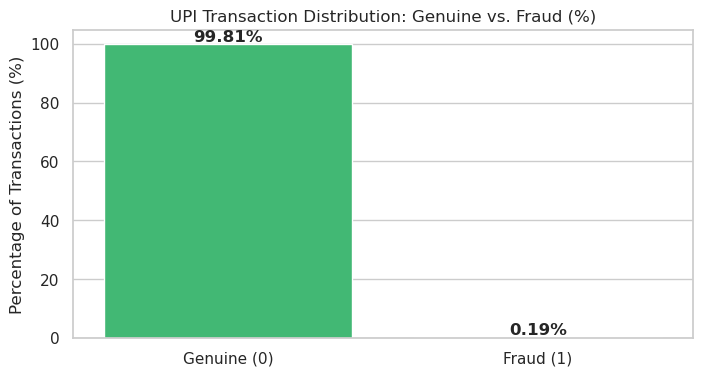

In [71]:
ax = sns.barplot(x=["Genuine (0)", "Fraud (1)"], y=fraud_pct.values, palette=["#2ecc71", "#e74c3c"])
ax.set_title("UPI Transaction Distribution: Genuine vs. Fraud (%)")
ax.set_ylabel("Percentage of Transactions (%)")
for i, v in enumerate(fraud_pct.values):
    ax.text(i, v + 1, f"{v:.2f}%", ha="center", fontweight="bold")

plt.show()

### Observation :- 

***Genuine*** transactions are 99.81% and ***Fraud*** Transactions are 0.19% 
Because of extreme class imbalance, I will ignore Accuracy and use Recall and PR-AUC to evaluate models, along with class weights (scale_pos_weight)

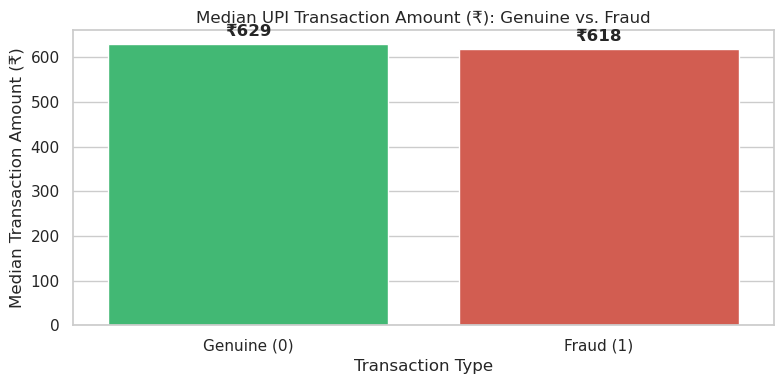

In [72]:
ax = sns.barplot(
    data=data,
    x="fraud_flag",
    y="amount (INR)",
    hue="fraud_flag",
    estimator="median",                
    errorbar=None,                     
    palette=["#2ecc71", "#e74c3c"],
    legend=False
)

ax.set_title("Median UPI Transaction Amount (₹): Genuine vs. Fraud")
ax.set_xlabel("Transaction Type")
ax.set_ylabel("Median Transaction Amount (₹)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Genuine (0)", "Fraud (1)"])
for container in ax.containers:
    ax.bar_label(container, fmt="₹%.0f", padding=4, fontweight="bold")

plt.tight_layout()
plt.show()


* he median UPI transaction amount is almost identical for Genuine (629 rupees) and Fraud (618 rupees)—a difference of just 11 rupees.

* Because the earlier average (mean) was more than double the median (1,310 rupees for Genuine and 1,500 rupees for Fraud), the data is heavily right-skewed by a small number of high-value transfers.

* Half of all fraud transactions happen at everyday amounts under 618 rupees, meaning fraudsters do not only target large transfers.

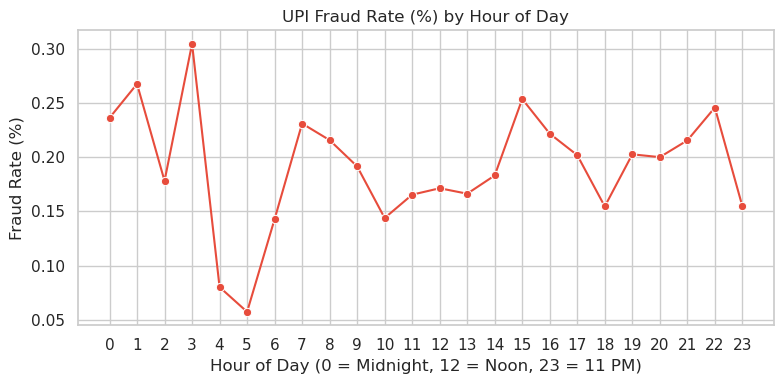

In [73]:
data["hour"] = pd.to_datetime(data["timestamp"]).dt.hour
hourly_fraud = data.groupby("hour")["fraud_flag"].mean() * 100
ax = sns.lineplot(x=hourly_fraud.index, y=hourly_fraud.values, marker="o", color="#e74c3c")
ax.set_title("UPI Fraud Rate (%) by Hour of Day")
ax.set_xlabel("Hour of Day (0 = Midnight, 12 = Noon, 23 = 11 PM)")
ax.set_ylabel("Fraud Rate (%)")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()


* The UPI fraud rate peaks at 3 AM (0.30%) and 1 AM (0.27%), and drops to its lowest at 5 AM (0.06%). Daytime hours stay mostly steady between 0.15% and 0.25%. However, the sharp zigzag between midnight and 5 AM suggests low transaction volume during late-night hours.

In [74]:
hourly_summary = data.groupby("hour").agg(
    total_txns=("fraud_flag", "count"),
    fraud_txns=("fraud_flag", "sum"),
    fraud_rate_pct=("fraud_flag", lambda x: round(x.mean() * 100, 3))
)
print(hourly_summary)

      total_txns  fraud_txns  fraud_rate_pct
hour                                        
0           3388           8           0.236
1           2244           6           0.267
2           1685           3           0.178
3           1314           4           0.304
4           1247           1           0.080
5           1742           1           0.057
6           3501           5           0.143
7           5630          13           0.231
8           8349          18           0.216
9          10450          20           0.191
10         13904          20           0.144
11         16328          27           0.165
12         17516          30           0.171
13         15038          25           0.166
14         11472          21           0.183
15         12624          32           0.253
16         13992          31           0.222
17         18340          37           0.202
18         20064          31           0.155
19         21232          43           0.203
20        

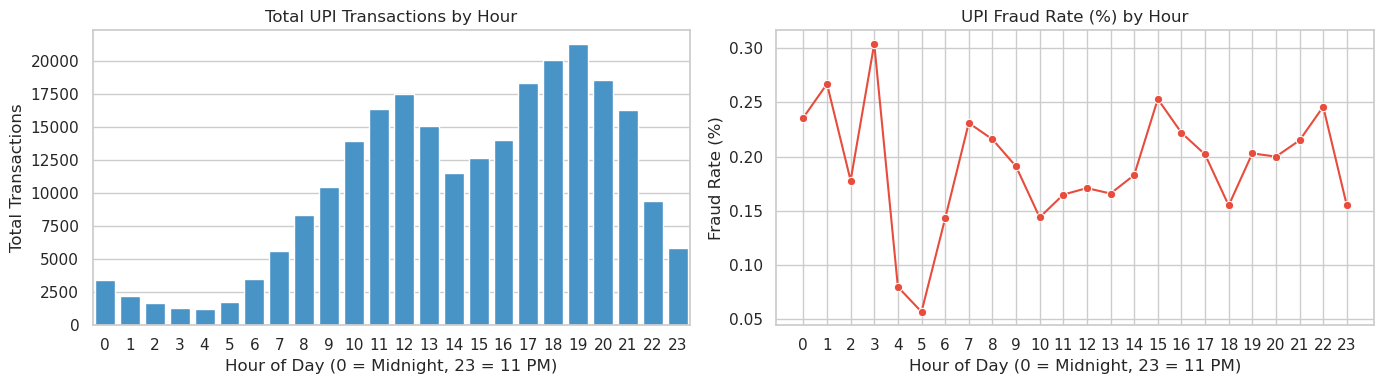

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=hourly_summary.index, y=hourly_summary["total_txns"], ax=axes[0], color="#3498db")
axes[0].set_title("Total UPI Transactions by Hour")
axes[0].set_xlabel("Hour of Day (0 = Midnight, 23 = 11 PM)")
axes[0].set_ylabel("Total Transactions")
sns.lineplot(x=hourly_summary.index, y=hourly_summary["fraud_rate_pct"], marker="o", ax=axes[1], color="#e74c3c")
axes[1].set_title("UPI Fraud Rate (%) by Hour")
axes[1].set_xlabel("Hour of Day (0 = Midnight, 23 = 11 PM)")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

## Observation
* **Peak UPI Traffic:** Transaction volume follows a normal Indian daily pattern—lowest between 2 AM and 5 AM (~1,200–1,700 txns/hour) and highest during evening hours from 5 PM to 8 PM, peaking at **7 PM (21,232 transactions)**.
* **3 AM Spike Is Low-Volume Noise:** Although **3 AM** has the highest fraud rate (**0.304%**), it is based on only **4 fraud cases** out of 1,314 transactions. Right next to it, 4 AM and 5 AM have only **1 fraud case** each (0.080% and 0.057%). This proves the late-night zigzag is caused by low volume, not a strong late-night fraud pattern.
* **Where Most Frauds Actually Happen:** In raw numbers, the highest fraud counts occur during busy evening hours—**7 PM (43 frauds)**, **5 PM (37 frauds)**, **8 PM (37 frauds)**, and **9 PM (35 frauds)**—while their fraud rates stay steady around **0.20%**.

## Action
* **Do not overfit to raw hours:** Because the 3 AM spike is just 4 cases, treating `hour = 3` as a high-risk rule will mislead the model.
* **Feature Engineering:** Group hours into broader, stable buckets (`Late Night`, `Morning`, `Afternoon`, `Evening`) or check if `hour` only becomes risky when combined with **high transaction amounts (₹)** or specific **merchant categories**.

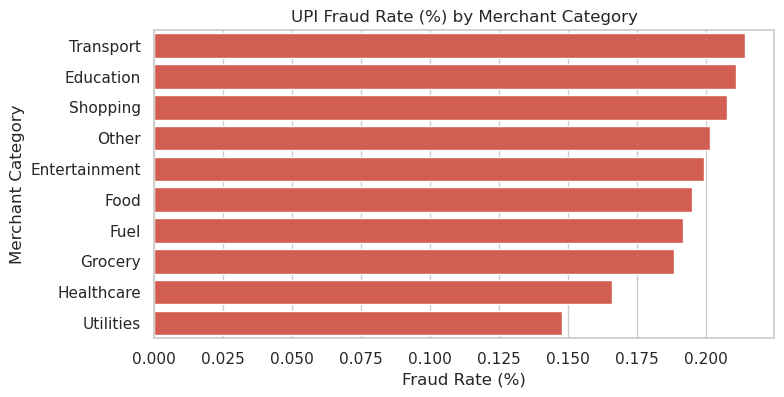

In [76]:
cat_fraud = (
    data.groupby("merchant_category")["fraud_flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
ax = sns.barplot(x=cat_fraud.values, y=cat_fraud.index, color="#e74c3c")
ax.set_title("UPI Fraud Rate (%) by Merchant Category")
ax.set_xlabel("Fraud Rate (%)")
ax.set_ylabel("Merchant Category")
plt.show()

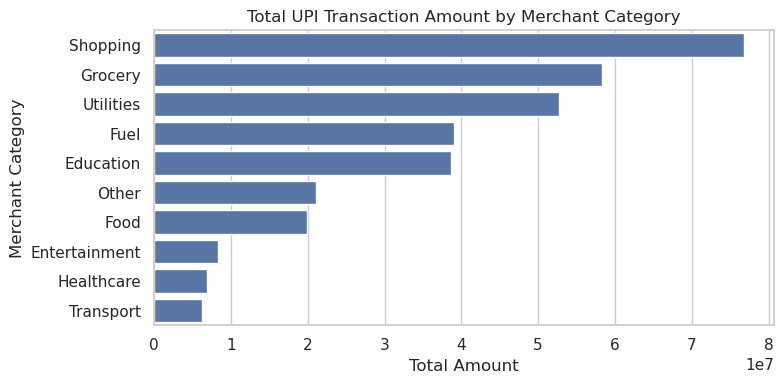

In [77]:
transaction_as_amount=(data.groupby("merchant_category")["amount (INR)"].sum().sort_values(ascending=False))
ax = sns.barplot(x=transaction_as_amount.values, y=transaction_as_amount.index)
ax.set_title("Total UPI Transaction Amount by Merchant Category")
ax.set_xlabel("Total Amount")
ax.set_ylabel("Merchant Category")
plt.tight_layout()
plt.show()

## Observation
* **Narrow Fraud Rate Range:** Across all 10 merchant categories, the UPI fraud rate stays within a tight range of **0.15% to 0.21%**. **Transport (~0.214%)**, **Education (~0.211%)**, and **Shopping (~0.208%)** have the highest rates, while **Utilities (~0.148%)** and **Healthcare (~0.166%)** have the lowest.
* **Where the Money Flows:** **Shopping (~₹7.7 Crore)**, **Grocery (~₹5.8 Crore)**, and **Utilities (~₹5.3 Crore)** account for the highest total transaction value, whereas **Transport (~₹60 Lakh)** and **Healthcare (~₹70 Lakh)** have the lowest.
* **Business Impact (Combining Both Charts):**
  * **Shopping** and **Education** are the highest-priority risk areas because they combine **high transaction value** with **above-average fraud rates**.
  * Although **Transport** has the highest fraud rate, its total volume is the smallest (~₹60 Lakh), so its overall rupee impact is much lower.
  * **Utilities** is the safest high-value category (~₹5.3 Crore with the lowest fraud rate at ~0.148%).

## Action
* **Keep `merchant_category` as a supporting feature:** Because the fraud rate difference is small (~0.06% spread), encode it (One-Hot or Target Encoding) and combine it with `amount (INR)` and `hour` rather than relying on it alone.
* **Next Deep-Dive:** Check **total fraud loss in ₹** (`data[data["fraud_flag"]==1].groupby("merchant_category")["amount (INR)"].sum()`) to confirm exactly which category costs the most money in fraud.

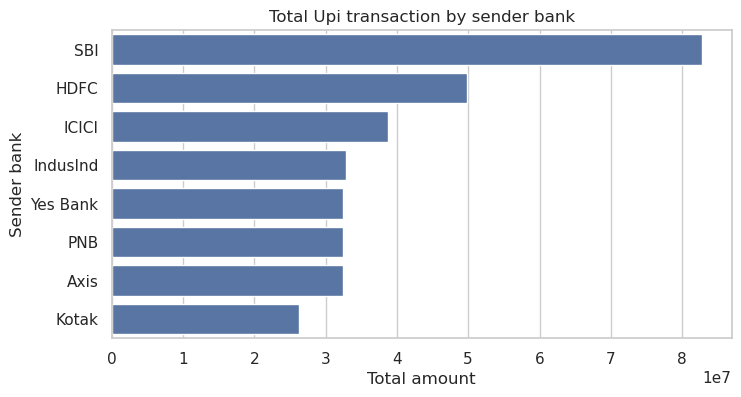

In [78]:
highest_amount_bank=(data.groupby("sender_bank")["amount (INR)"].sum().sort_values(ascending=False))
ax=sns.barplot(x=highest_amount_bank.values,y=highest_amount_bank.index)
ax.set_title("Total Upi transaction by sender bank")
ax.set_xlabel("Total amount")
ax.set_ylabel("Sender bank")
plt.show()

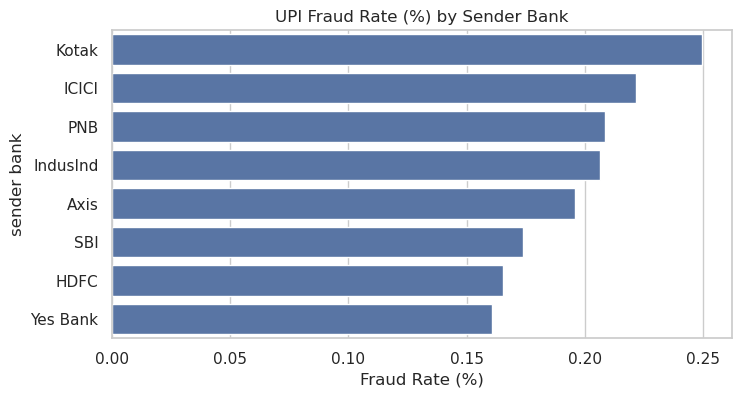

In [79]:
highest_fraud_cases=(data.groupby("sender_bank")["fraud_flag"].mean().mul(100).sort_values(ascending=False))
axis=sns.barplot(x=highest_fraud_cases.values,y=highest_fraud_cases.index)
axis.set_title("UPI Fraud Rate (%) by Sender Bank")
axis.set_xlabel("Fraud Rate (%)")
axis.set_ylabel("sender bank")
plt.show()

## Observation
* **Top Banks by Transaction Value:** **SBI (~₹8.3 Crore)** leads total UPI transaction value by a wide margin, followed by **HDFC (~₹5.0 Crore)** and **ICICI (~₹3.9 Crore)**. **Kotak (~₹2.6 Crore)** has the lowest total value.
* **Top Banks by Fraud Rate (%):** Fraud rates across banks range from **0.16% to 0.25%**. **Kotak (~0.25%)** and **ICICI (~0.22%)** have the highest fraud rates, while **Yes Bank (~0.16%)**, **HDFC (~0.165%)**, and **SBI (~0.173%)** have the lowest.
* **Volume vs. Risk Contrast:** High-volume banks like **SBI** and **HDFC** maintain low fraud rates, whereas **Kotak** has the highest fraud rate despite the lowest total value. **ICICI** is a key risk area because it ranks high in both total value (#3) and fraud rate (#2).

## Action
* **Fix Chart 2 labels** to clearly state `Fraud Rate (%)` instead of `Fraud`.
* **Check raw fraud count and total fraud loss (₹)** per bank to confirm whether **SBI** (huge volume, low rate) or **ICICI / Kotak** (higher rate) actually loses more total rupees to fraud.
* **Keep `sender_bank` for modeling** using One-Hot or Target Encoding, and test interaction features like `sender_bank` + `amount (INR)`.

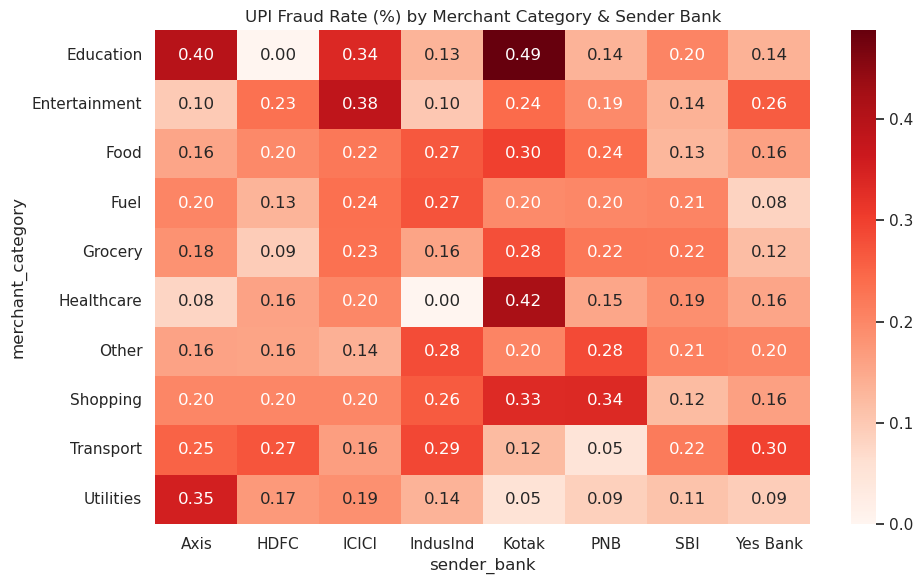

In [80]:
pivot_fraud = pd.pivot_table(
    data,
    values="fraud_flag",
    index="merchant_category",
    columns="sender_bank",
    aggfunc="mean"
) * 100
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_fraud, annot=True, fmt=".2f", cmap="Reds")
plt.title("UPI Fraud Rate (%) by Merchant Category & Sender Bank")
plt.tight_layout()
plt.show()

## Observation
* **Top High-Risk Combinations:** The highest UPI fraud rates occur in **Kotak + Education (0.49%)**, **Kotak + Healthcare (0.42%)**, **Axis + Education (0.40%)**, and **ICICI + Entertainment (0.38%)**.
* **Bank-Level Consistency:** **SBI** remains consistently low and stable across every merchant category (0.11%–0.22%), whereas **Kotak** shows elevated fraud rates across multiple categories (Education, Healthcare, Shopping, Food).
* **Category Anomaly:** **Utilities** has a very low fraud rate for almost all banks (0.05%–0.19%), but spikes sharply for **Axis Bank (0.35%)**.
* **High-Value Business Risk:** Because **Shopping** carries the highest total rupee volume (~₹7.7 Crore), the spikes in **PNB + Shopping (0.34%)** and **Kotak + Shopping (0.33%)** are especially important for preventing actual ₹ losses.

## Action
* **Verify Sample Size Before Trusting Extremes:** Because splitting the dataset into 80 cells leaves relatively few transactions per cell, check transaction counts (`aggfunc="count"`) for `Kotak + Education` and `HDFC + Education` to confirm these aren't small-sample noise.
* **Feature Engineering:** If the counts are solid, create an interaction feature (`bank_category = sender_bank + "_" + merchant_category`) or let tree-based models (**XGBoost / LightGBM**) automatically learn these Bank × Category combinations.

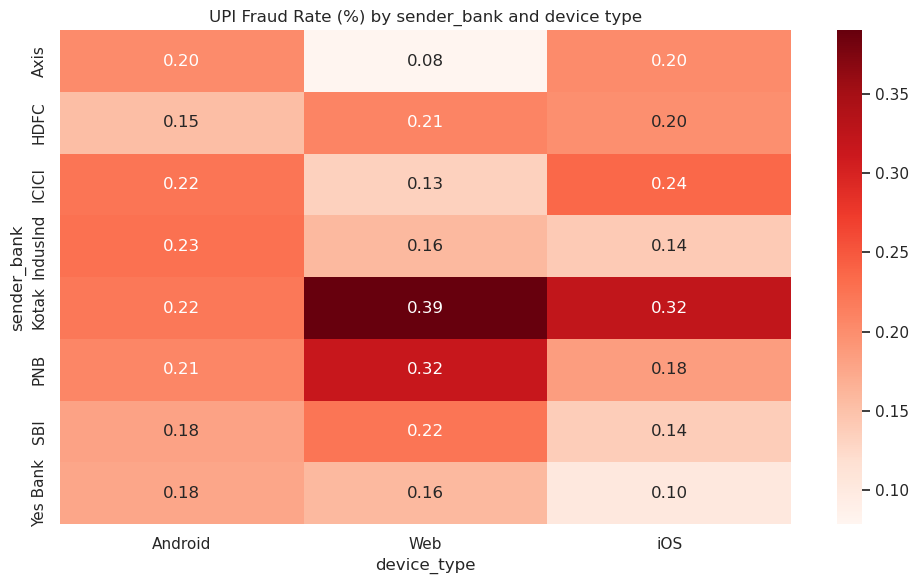

In [81]:
pivot_fraud = pd.pivot_table(
    data,
    values="fraud_flag",
    index="sender_bank",
    columns="device_type",
    aggfunc="mean"
) * 100
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_fraud, annot=True, fmt=".2f", cmap="Reds")
plt.title("UPI Fraud Rate (%) by sender_bank and device type")
plt.tight_layout()
plt.show()

## Observation
* **Highest Risk Hotspots:** **Kotak + Web (0.39%)**, **Kotak + iOS (0.32%)**, and **PNB + Web (0.32%)** have the highest UPI fraud rates on the chart.
* **Safest Combinations:** **Axis + Web (0.08%)** and **Yes Bank + iOS (0.10%)** record the lowest fraud rates.
* **Android Is Steady, Web Is Noisy:**
  * **Android** stays very consistent across all 8 banks (**0.15% to 0.23%**), likely because Android handles the majority of everyday Indian UPI traffic.
  * **Web** shows the widest swings—from **0.08%** (Axis) all the way up to **0.39%** (Kotak)—which usually happens when a channel has much lower transaction volume.
* **Bank-Level Pattern:** **Yes Bank** (0.10%–0.18%) and **SBI** (0.14%–0.22%) stay consistently low across every device, whereas **Kotak** stays elevated across all three devices.

## Action
* **Check Volume Behind Web Spikes:** Run a quick `aggfunc="count"` pivot table on `sender_bank` × `device_type` to see how many transactions actually happened on **Web** for Kotak and PNB before treating 0.39% as a major risk rule.
* **Feature Engineering:** If the Web and iOS counts are large enough, create a combined interaction feature (`sender_bank + "_" + device_type`) or let tree-based models (**XGBoost / LightGBM**) capture these bank-device combinations automatically.

In [82]:
data["time_slot"] = pd.cut(
    data["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Late Night\n(12AM-5AM)", "Morning\n(6AM-11AM)", "Afternoon\n(12PM-5PM)", "Evening\n(6PM-11PM)"]
)

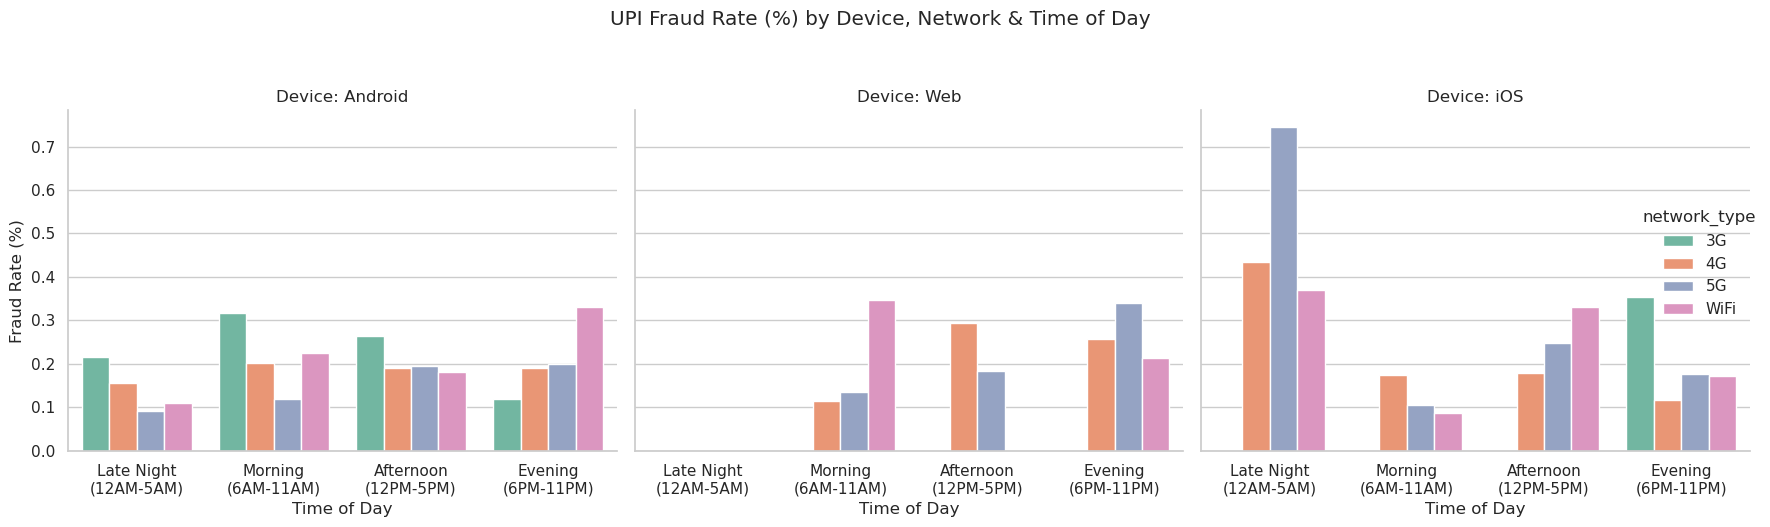

In [83]:
summary_4d = data.groupby(
    ["device_type", "network_type", "time_slot"], observed=False
).agg(
    total_txns=("fraud_flag", "count"),
    fraud_rate_pct=("fraud_flag", lambda x: round(x.mean() * 100, 3))
).reset_index()
g = sns.catplot(
    data=summary_4d,
    kind="bar",
    x="time_slot",
    y="fraud_rate_pct",
    hue="network_type",
    col="device_type",
    height=5,
    aspect=1.1,
    palette="Set2"
)

g.set_axis_labels("Time of Day", "Fraud Rate (%)")
g.set_titles("Device: {col_name}")
g.fig.suptitle("UPI Fraud Rate (%) by Device, Network & Time of Day", y=1.05)
plt.tight_layout()
plt.show()

In [84]:
data=data.drop("transaction id",axis=1)

In [85]:
data

,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,hour,time_slot
0,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,15,Afternoon\n(12PM-5PM)
1,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,6,Morning\n(6AM-11AM)
2,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,13,Afternoon\n(12PM-5PM)
3,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,10,Morning\n(6AM-11AM)
4,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,19,Evening\n(6PM-11PM)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0,22,Evening\n(6PM-11PM)
249996,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1,2,Late Night\n(12AM-5AM)
249997,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0,16,Afternoon\n(12PM-5PM)
249998,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0,13,Afternoon\n(12PM-5PM)


In [88]:
text_cols=data.select_dtypes(include="object").columns
for col in text_cols:
    data[col] = data[col].str.strip()

In [92]:
data

,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,hour,time_slot
0,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,15,Afternoon\n(12PM-5PM)
1,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,6,Morning\n(6AM-11AM)
2,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,13,Afternoon\n(12PM-5PM)
3,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,10,Morning\n(6AM-11AM)
4,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,19,Evening\n(6PM-11PM)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0,22,Evening\n(6PM-11PM)
249996,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1,2,Late Night\n(12AM-5AM)
249997,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0,16,Afternoon\n(12PM-5PM)
249998,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0,13,Afternoon\n(12PM-5PM)


In [93]:
data=data.rename(columns={"amount (INR)":"amount_inr"})
data = data[data["amount_inr"] > 0]

In [94]:
data

,timestamp,transaction type,merchant_category,amount_inr,transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,hour,time_slot
0,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,15,Afternoon\n(12PM-5PM)
1,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,6,Morning\n(6AM-11AM)
2,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,13,Afternoon\n(12PM-5PM)
3,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,10,Morning\n(6AM-11AM)
4,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,19,Evening\n(6PM-11PM)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0,22,Evening\n(6PM-11PM)
249996,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1,2,Late Night\n(12AM-5AM)
249997,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0,16,Afternoon\n(12PM-5PM)
249998,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0,13,Afternoon\n(12PM-5PM)


In [96]:
data=data.rename(columns={"transaction type":"transaction_type"})

In [97]:
data

,timestamp,transaction_type,merchant_category,amount_inr,transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,hour,time_slot
0,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,15,Afternoon\n(12PM-5PM)
1,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,6,Morning\n(6AM-11AM)
2,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,13,Afternoon\n(12PM-5PM)
3,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,10,Morning\n(6AM-11AM)
4,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,19,Evening\n(6PM-11PM)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0,22,Evening\n(6PM-11PM)
249996,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1,2,Late Night\n(12AM-5AM)
249997,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0,16,Afternoon\n(12PM-5PM)
249998,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0,13,Afternoon\n(12PM-5PM)


In [98]:
data.shape

(250000, 18)

In [103]:
data.to_csv("/home/saurabh/AI_PROJECTS/UPI_fraud_prediction/data/preprocessed/upi_cleaned.csv", index=False)
print("Saved successfully!")

Saved successfully!
